In [60]:
%load_ext autoreload
%autoreload 2

In [ ]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import random
import seaborn as sns
import numpy as np

from tqdm import tqdm
from itertools import product
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import StratifiedShuffleSplit, train_test_split
from sklearn.metrics import confusion_matrix
from imblearn.under_sampling import RandomUnderSampler

from src.metricas import tabla_metricas, evaluar_metricas_clasificacion, evaluar_metricas_regresion
from src.utils import df_features_to_numpy, df_target_to_numpy, mini_grid_search_logistica, mini_grid_search_logistica_undersampling
from src.graficos import plot_confusion_matrix, plot_learning_curves_linear_regression, plot_learning_curves_logistic_regression, plot_comparacion_metricas, plot_feature_importance_regression
from src.splitting import split_estratificado_autor

# Cargo el dataset ya procesado

In [3]:
chunks_train = pd.read_json("set_train_1.json", lines=True, chunksize=100_000)

chunk_list = []
for chunk in chunks_train:
    chunk_list.append(chunk)

df_train = pd.concat(chunk_list, ignore_index=True)
print(df_train.shape)
#REPETIR PARA EL TRAIN, VAL Y TEST
#TODO: lo hago apra cargar el de set de train --> clari, no se si te sirve o no, podemso comentarlo

(462879, 62)


In [4]:
chunks_val = pd.read_json("set_val_1.json", lines=True, chunksize=100_000)

chunk_list = []
for chunk in chunks_val:
    chunk_list.append(chunk)

df_val = pd.concat(chunk_list, ignore_index=True)
print(df_val.shape)
#REPETIR PARA EL TRAIN, VAL Y TEST
#TODO: lo hago apra cargar el de set de train --> clari, no se si te sirve o no, podemso comentarlo

(81959, 62)


In [5]:
chunks_test = pd.read_json("set_test_1.json", lines=True, chunksize=100_000)

chunk_list = []
for chunk in chunks_test:
    chunk_list.append(chunk)

df_test = pd.concat(chunk_list, ignore_index=True)
print(df_test.shape)
#REPETIR PARA EL TRAIN, VAL Y TEST
#TODO: lo hago apra cargar el de set de train --> clari, no se si te sirve o no, podemso comentarlo

(94653, 62)


## Preparacion de los datos

In [7]:
generos = ["fiction", "non fiction", "fantasy", "science fiction", "mystery", "thriller", "romance", "horror", "historical", "young adult", "children", "adventure", "contemporary", "dystopian", "paranormal", "urban", "crime", "biography", "memoir", "self help", "history", "psychology", "poetry", "classics", "graphic novel", "short stories", "humor", "religion"]
features = ["is_series", "publication_year", "num_pages", 'AUDIO', 'COMIC', 'EBOOK', 'HARDCOVER', 'OTHER', 'PAPERBACK', "language_code_", "language_code_ang", "language_code_en", "language_code_en-CA", "language_code_en-GB", "language_code_en-US", "language_code_eng", "language_code_enm", "language_code_gem", "language_code_sco", "cantidad_generos"] + generos #'format_group_UNKNOWN' la saco por el one hot en regresion

#Me quedo solo con las features necesarias para el modelo base y las estandarizo
dfs = [df_train, df_val, df_test]
y_train_regresion, y_val_regresion, y_test_regresion = df_target_to_numpy("average_rating", dfs)
y_train_clasificacion, y_val_clasificacion, y_test_clasificacion = df_target_to_numpy("estrellas", dfs)
X_train, X_val, X_test = df_features_to_numpy(features, dfs)

#estandarizo los datos
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val) #escala X_val con los valores sacados de X_train
#TODO: escalar el X_test

## Regresion Lineal con features basicas

In [8]:
modeloBaseRegresionLineal = LinearRegression() 
modeloBaseRegresionLineal.fit(X_train_scaled, y_train_regresion) #Minimiza MSE

y_pred_train_modeloBaseRegresionLineal = modeloBaseRegresionLineal.predict(X_train_scaled)
y_pred_val_modeloBaseRegresionLineal = modeloBaseRegresionLineal.predict(X_val_scaled)

metricas_train = evaluar_metricas_regresion(y_pred_train_modeloBaseRegresionLineal, y_train_regresion)
metricas_val = evaluar_metricas_regresion(y_pred_val_modeloBaseRegresionLineal, y_val_regresion)
print(tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"]))

         Train  Validation
MSE   0.127286    0.127855
RMSE  0.356771    0.357568
MAE   0.276945    0.277271
R²    0.099946    0.098599


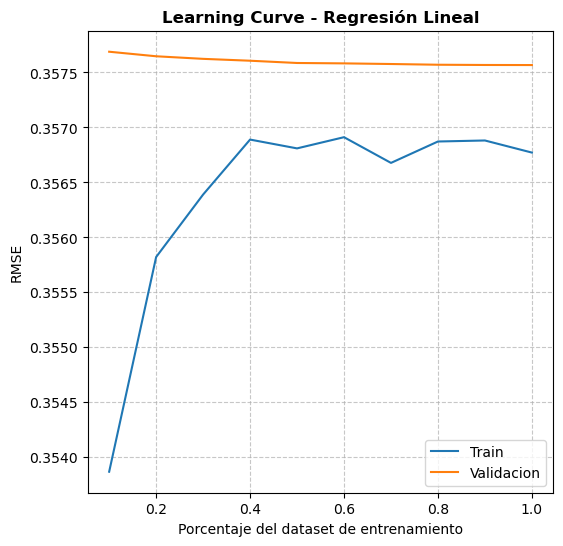

In [9]:
plot_learning_curves_linear_regression(X_train_scaled, y_train_regresion, X_val_scaled, y_val_regresion)

A simple vista, podemos notar que todas las metricas de train y val son casi iguales. Es decir, que no evidencia comportmaiento de overfitting, indicando que generaliza bastante bien.

Ademas, que el MAE valga en validacion 0.2777, significa que, en promedio, el modelo se equivoca aproximadamente 0.28 puntos de rating (lo cual no es tan grave). Y como la diferencia entre RMSE y MAE no es tan grande, esto indica que no parece haber muchas predicciones extremadamente malas.

Lo unico que llama la atencion es el R^2 tan bajo, signfica que el modelo puede explicar un bajo porcentaje de la variablidad del rating.

Analizamos la feature importance:

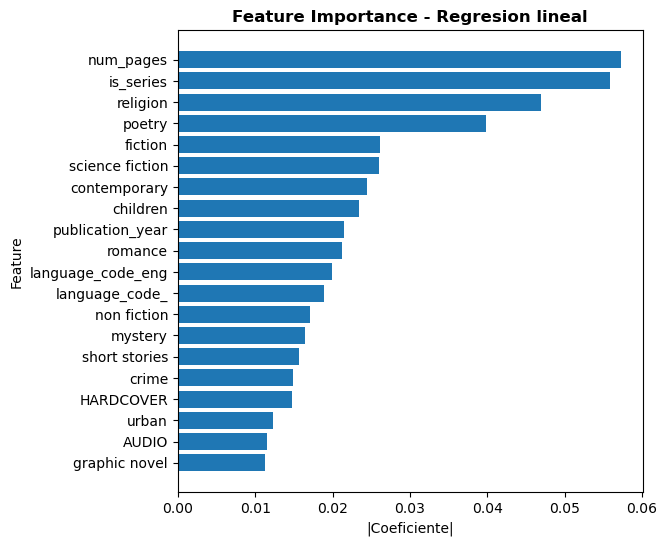

In [10]:
coeficientes_regresion_lineal = pd.DataFrame({"feature": features, "coef": modeloBaseRegresionLineal.coef_})
coeficientes_regresion_lineal["abs_coef"] = np.abs(coeficientes_regresion_lineal["coef"])
coeficientes_regresion_lineal = coeficientes_regresion_lineal.sort_values("abs_coef", ascending = False)
plot_feature_importance_regression(coeficientes_regresion_lineal, "lineal")

## Regresion Logistica con features basicas

              Train  Validation
Accuracy   0.817430    0.814322
Precision  0.364518    0.427180
Recall     0.201463    0.201985
F1         0.182942    0.183565


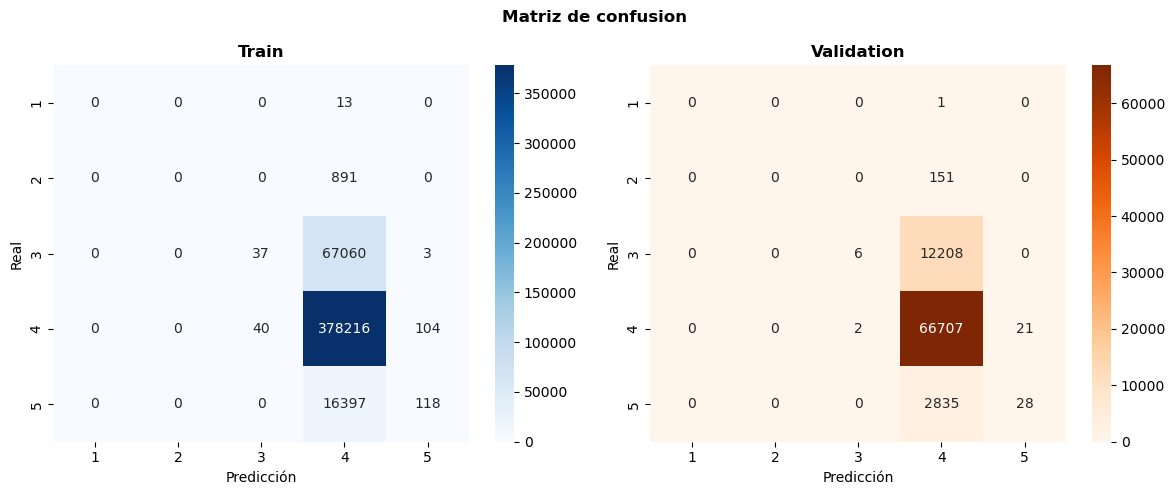

In [65]:
modeloBaseRegresionLogistica = LogisticRegression(max_iter = 1000)
modeloBaseRegresionLogistica.fit(X_train_scaled, y_train_clasificacion)

y_pred_train_modeloBaseRegresionLogistica = modeloBaseRegresionLogistica.predict(X_train_scaled)
y_pred_val_modeloBaseRegresionLogistica = modeloBaseRegresionLogistica.predict(X_val_scaled)

metricas_train_base = evaluar_metricas_clasificacion(y_pred_train_modeloBaseRegresionLogistica, y_train_clasificacion)
metricas_val_base = evaluar_metricas_clasificacion(y_pred_val_modeloBaseRegresionLogistica, y_val_clasificacion)
tabla_metricas_regresion_logistica_base = tabla_metricas(metricas_train_base, metricas_val_base, ["Accuracy", "Precision", "Recall", "F1"])
print(tabla_metricas_regresion_logistica_base)

labels = [1, 2, 3, 4, 5]
cm_train = confusion_matrix(y_train_clasificacion, y_pred_train_modeloBaseRegresionLogistica, labels = labels)
cm_val = confusion_matrix(y_val_clasificacion, y_pred_val_modeloBaseRegresionLogistica, labels = labels)
plot_confusion_matrix(cm_train, cm_val, labels)

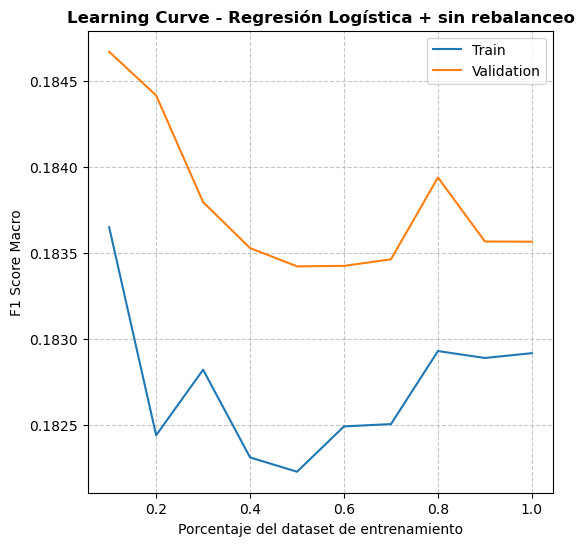

In [12]:
plot_learning_curves_logistic_regression(X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion, "sin rebalanceo")

Analizamos la feature importance:

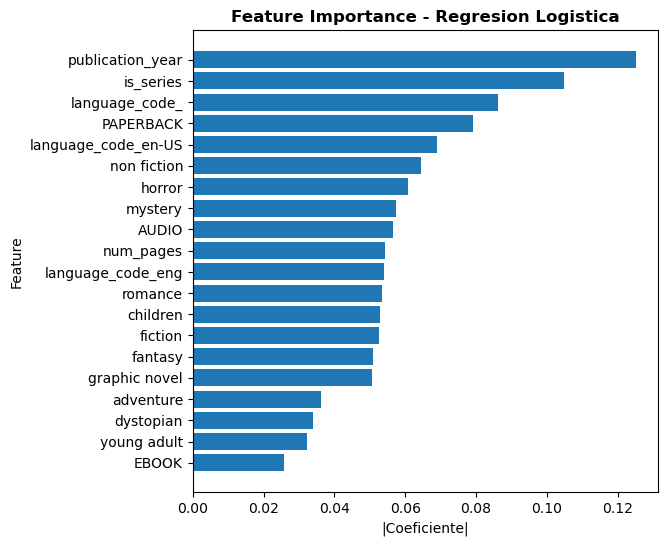

In [13]:
coeficientes_regresion_log = pd.DataFrame({"feature": features, "coef": modeloBaseRegresionLogistica.coef_[0]})
coeficientes_regresion_log["abs_coef"] = np.abs(coeficientes_regresion_log["coef"])
coeficientes_regresion_log = coeficientes_regresion_log.sort_values("abs_coef", ascending = False)
plot_feature_importance_regression(coeficientes_regresion_log, "Logistica")

### Balanceo de clases

#### El primer balanceo que intento es el predeterminado de scikit learn

              Train  Validation
Accuracy   0.432258    0.428995
Precision  0.244487    0.243617
Recall     0.557419    0.547840
F1         0.207628    0.206081


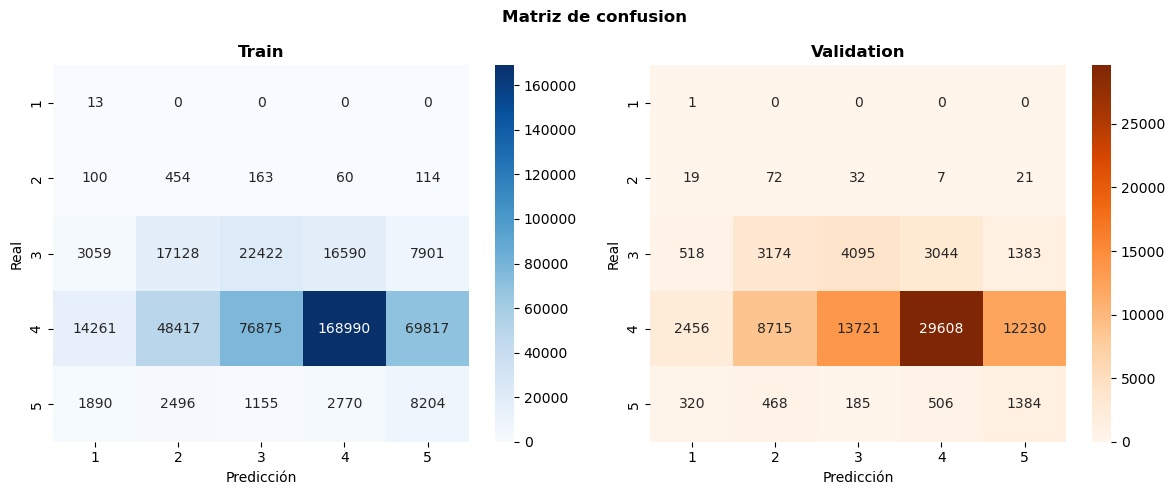

In [66]:
rebalanceo_1 = LogisticRegression(max_iter = 1000, class_weight = "balanced")
rebalanceo_1.fit(X_train_scaled, y_train_clasificacion)

y_pred_train_rebalanceo_1 = rebalanceo_1.predict(X_train_scaled)
y_pred_val_rebalanceo_1 = rebalanceo_1.predict(X_val_scaled)

metricas_train_balanced = evaluar_metricas_clasificacion(y_pred_train_rebalanceo_1, y_train_clasificacion)
metricas_val_balanced = evaluar_metricas_clasificacion(y_pred_val_rebalanceo_1, y_val_clasificacion)
tabla_metricas_regresion_logistica_1 = tabla_metricas(metricas_train_balanced, metricas_val_balanced, ["Accuracy", "Precision", "Recall", "F1"])
print(tabla_metricas_regresion_logistica_1)

cm_train = confusion_matrix(y_train_clasificacion, y_pred_train_rebalanceo_1, labels = labels)
cm_val = confusion_matrix(y_val_clasificacion, y_pred_val_rebalanceo_1, labels = labels)
plot_confusion_matrix(cm_train, cm_val, labels)

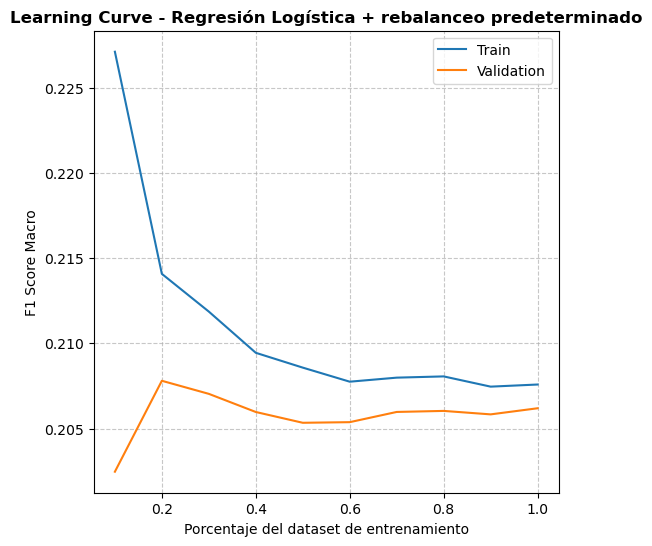

In [15]:
plot_learning_curves_logistic_regression(X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion, "rebalanceo predeterminado", modelo_class_weight = "balanced")

Analizamos la feature importance:

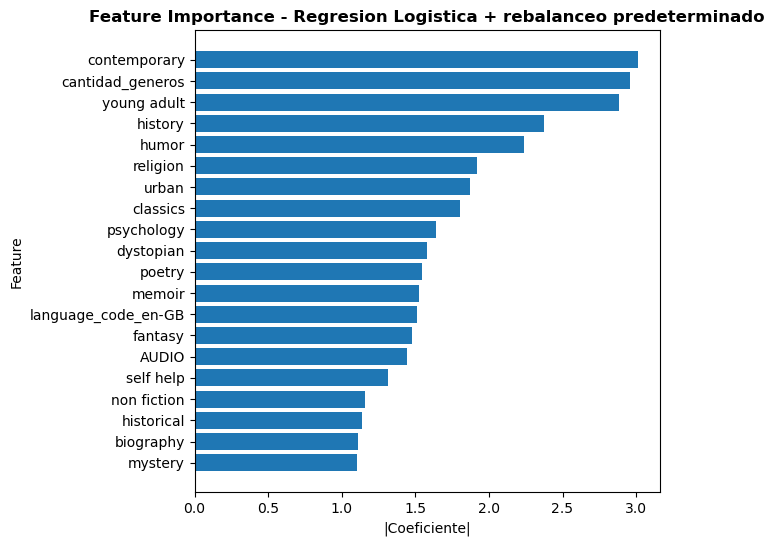

In [16]:
coeficientes_regresion_log_balanced = pd.DataFrame({"feature": features, "coef": rebalanceo_1.coef_[0]})
coeficientes_regresion_log_balanced["abs_coef"] = np.abs(coeficientes_regresion_log_balanced["coef"])
coeficientes_regresion_log_balanced = coeficientes_regresion_log_balanced.sort_values("abs_coef", ascending = False)
plot_feature_importance_regression(coeficientes_regresion_log_balanced, "Logistica + rebalanceo predeterminado")

#### Ahora intento ponerles pesos personalizados

In [ ]:
pesos_clase_1 = [5, 8, 10, 40]
pesos_clase_2 = [1, 2, 5, 10]
peso_clase_3 = 2
peso_clase_4 = 1
pesos_clase_5 = [1, 3, 5, 7]

resultados_reg_log_pesos = mini_grid_search_logistica(X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion, pesos_clase_1, pesos_clase_2, peso_clase_3, peso_clase_4, pesos_clase_5)
df_resultados_reg_log_pesos = pd.DataFrame(resultados_reg_log_pesos)
df_resultados_reg_log_pesos = df_resultados_reg_log_pesos.sort_values(by = ["f1", "recall", "precision"], ascending = False)
mejor_comb_pesos = df_resultados_reg_log_pesos.iloc[0]
pesos_finales_reg_log_pesos = {1: int(mejor_comb_pesos["peso_1"]), 2: int(mejor_comb_pesos["peso_2"]), 3: peso_clase_3, 4: peso_clase_4, 5: int(mejor_comb_pesos["peso_5"])}
print(f"Pesos finales: {pesos_finales_reg_log_pesos}")

              Train  Validation
Accuracy   0.791527    0.789151
Precision  0.282944    0.287356
Recall     0.252237    0.252599
F1         0.248432    0.249077


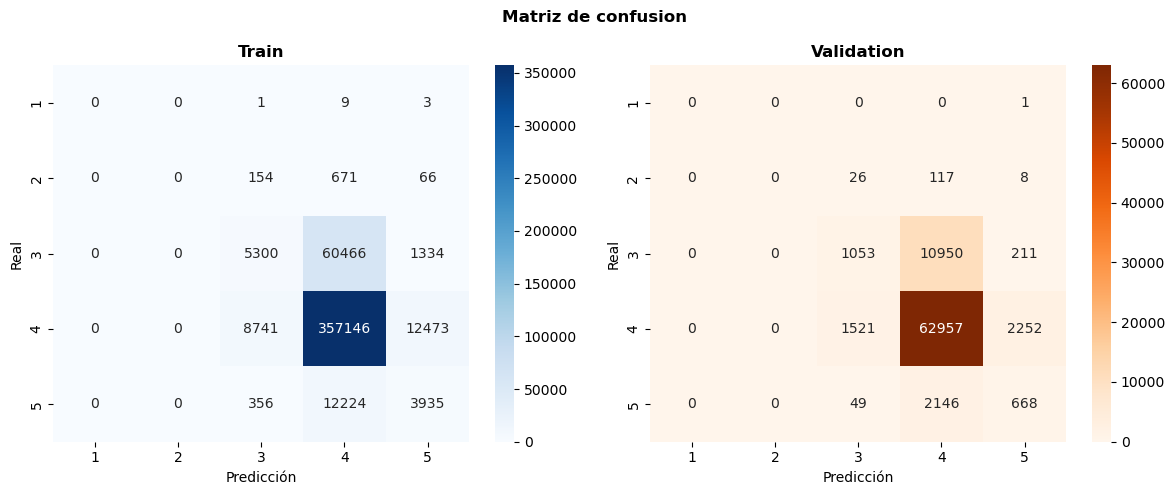

In [68]:
rebalanceo_2 = LogisticRegression(max_iter = 1000, class_weight = pesos_finales_reg_log_pesos)
rebalanceo_2.fit(X_train_scaled, y_train_clasificacion)

y_pred_train_rebalanceo_2 = rebalanceo_2.predict(X_train_scaled)
y_pred_val_rebalanceo_2 = rebalanceo_2.predict(X_val_scaled)

metricas_train_manual = evaluar_metricas_clasificacion(y_pred_train_rebalanceo_2, y_train_clasificacion)
metricas_val_manual = evaluar_metricas_clasificacion(y_pred_val_rebalanceo_2, y_val_clasificacion)
tabla_metricas_regresion_logistica_2 = tabla_metricas(metricas_train_manual, metricas_val_manual, ["Accuracy", "Precision", "Recall", "F1"])
print(tabla_metricas_regresion_logistica_2)

cm_train = confusion_matrix(y_train_clasificacion, y_pred_train_rebalanceo_2, labels = labels)
cm_val = confusion_matrix(y_val_clasificacion, y_pred_val_rebalanceo_2)
plot_confusion_matrix(cm_train, cm_val, labels)

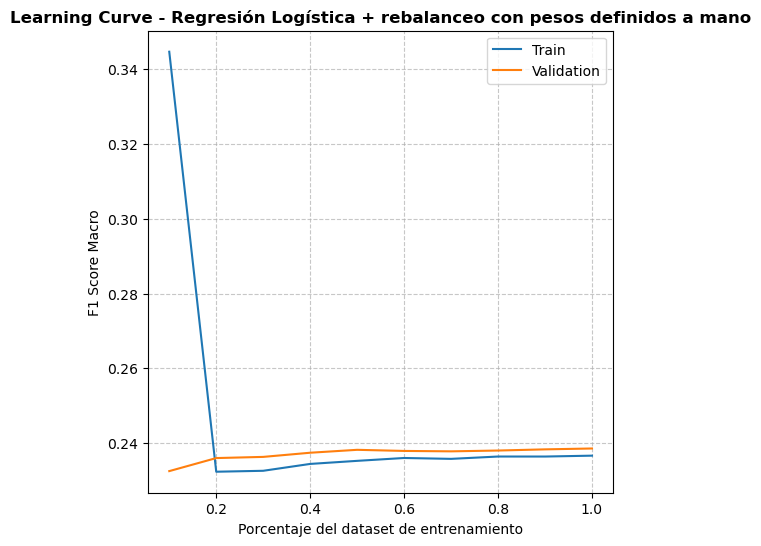

In [ ]:
plot_learning_curves_logistic_regression(X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion, "rebalanceo con pesos definidos a mano", modelo_class_weight = pesos_finales_reg_log_pesos)

Analizamos la feature importance:

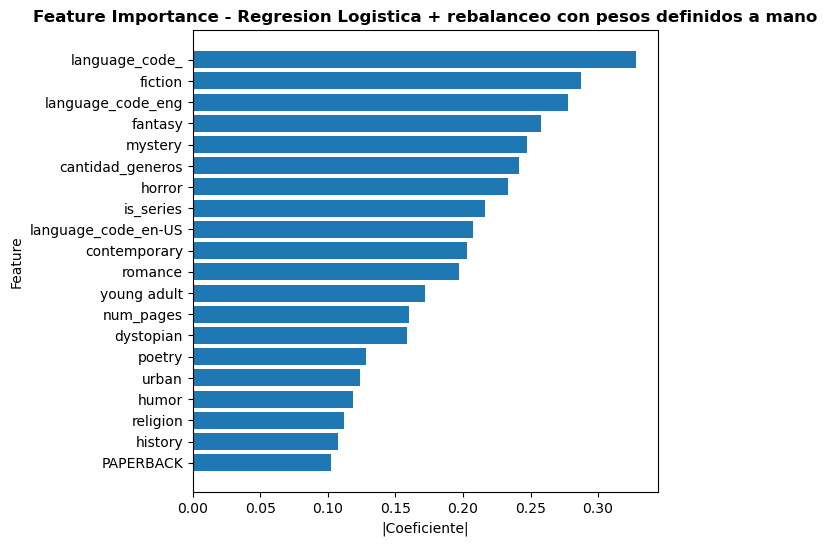

In [44]:
coeficientes_regresion_log_personalizado = pd.DataFrame({"feature": features, "coef": rebalanceo_2.coef_[0]})
coeficientes_regresion_log_personalizado["abs_coef"] = np.abs(coeficientes_regresion_log_personalizado["coef"])
coeficientes_regresion_log_personalizado = coeficientes_regresion_log_personalizado.sort_values("abs_coef", ascending = False)
plot_feature_importance_regression(coeficientes_regresion_log_personalizado, "Logistica + rebalanceo con pesos definidos a mano")

#### Undersamplig + cost:

In [31]:
pd.Series(y_train_clasificacion).value_counts().sort_index()

1        13
2       891
3     67100
4    378360
5     16515
Name: count, dtype: int64

Como podemos ver, la cantidad de muestras que pertenecen a la clase 4 es significativamente mayor a las de las demas clases. Es por esto que no vamos a aplicar un undersampling fuerte ya que, si nos quedamos con 70000 muestras, por ejemplo, estamos perdiendo demasiadas muestras que el modelo podria aprovechar para aprender mejor. 

Ademas, notamos que la clase 1 esta casi vacia. Esto quiere decir que, aunque le pongamos un alto peso a esa clase, va a ser muy dificil para el modelo aprender bien esa categoria. Por lo tanto, vamos a tener que maenjar el trade-off entre la importancia que le damos a esas muestras, sin causar que el modelo se las termine memorizando.

In [ ]:
#Reutilizamos las mismas opciones de los pesos que en el modelo anterior:
cantidad_clase_4 = [150000, 225000, 300000]
resultados_reg_log_under = mini_grid_search_logistica_undersampling(X_train, y_train_clasificacion, X_val, y_val_clasificacion, cantidad_clase_4, pesos_clase_1, pesos_clase_2, peso_clase_3, peso_clase_4, pesos_clase_5)
df_resultados_reg_log_under = pd.DataFrame(resultados_reg_log_under)
df_resultados_reg_log_under = df_resultados_reg_log_under.sort_values(by = ["f1", "recall", "precision"], ascending = False)
mejor_comb_under = df_resultados_reg_log_under.iloc[0]
print(f"Mejor cantidad para undersampling: {mejor_comb_under}")
pesos_finales_reg_log_under = {1: int(mejor_comb_under["peso_1"]), 2: int(mejor_comb_under["peso_2"]), 3: peso_clase_3, 4: peso_clase_4, 5: int(mejor_comb_under["peso_5"])}
print(f"Pesos finales: {pesos_finales_reg_log_under}")

              Train  Validation
Accuracy   0.729901    0.725521
Precision  0.271378    0.269997
Recall     0.280184    0.279348
F1         0.275165    0.273983


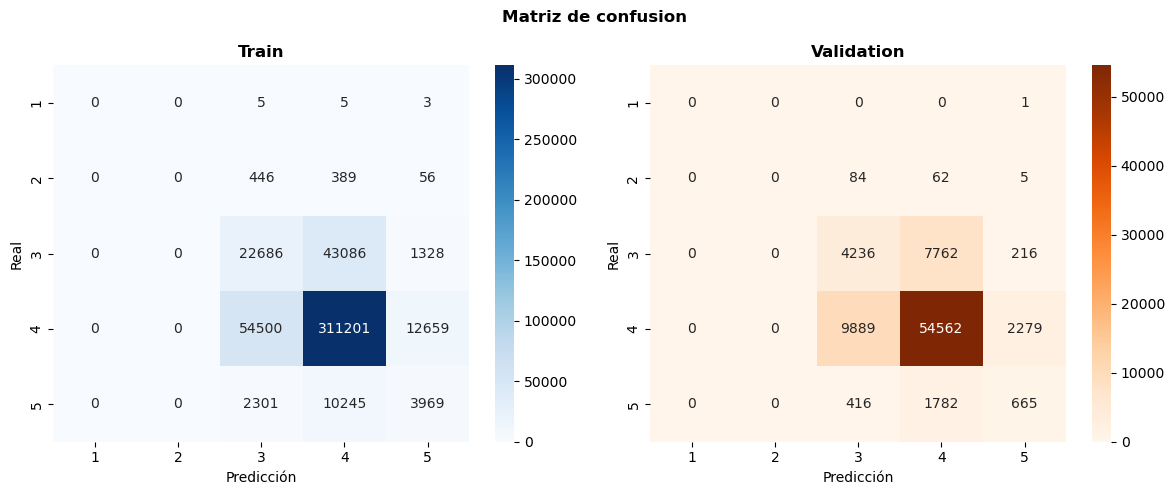

In [69]:
undersampling = RandomUnderSampler(sampling_strategy = {4: int(mejor_comb_under["cantidad"])}, random_state = 42)
X_res, y_res = undersampling.fit_resample(X_train, y_train_clasificacion) 

scaler = StandardScaler()
X_res_scaled = scaler.fit_transform(X_res)
X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)

rebalanceo_3 = LogisticRegression(class_weight = pesos_finales_reg_log_under, max_iter = 1000)
rebalanceo_3.fit(X_res_scaled, y_res)

y_pred_train_rebalanceo_3 = rebalanceo_3.predict(X_train_scaled)
y_pred_val_rebalanceo_3 = rebalanceo_3.predict(X_val_scaled)

metricas_train_undersampling = evaluar_metricas_clasificacion(y_pred_train_rebalanceo_3, y_train_clasificacion)
metricas_val_undersampling = evaluar_metricas_clasificacion(y_pred_val_rebalanceo_3, y_val_clasificacion)
tabla_metricas_regresion_logistica_3 = tabla_metricas(metricas_train_undersampling, metricas_val_undersampling, ["Accuracy", "Precision", "Recall", "F1"])
print(tabla_metricas_regresion_logistica_3)

cm_train = confusion_matrix(y_train_clasificacion, y_pred_train_rebalanceo_3, labels = labels)
cm_val = confusion_matrix(y_val_clasificacion, y_pred_val_rebalanceo_3, labels = labels)
plot_confusion_matrix(cm_train, cm_val, labels)

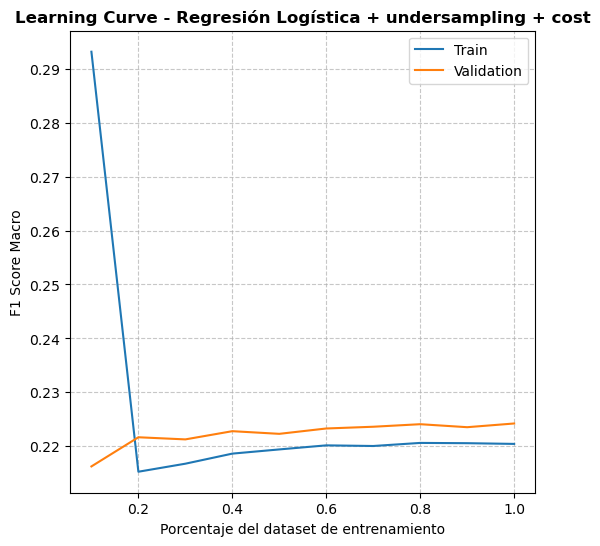

In [ ]:
plot_learning_curves_logistic_regression(X_res_scaled, y_res, X_val_scaled, y_val_clasificacion, "undersampling + cost", modelo_class_weight = pesos_finales_reg_log_under)

Analizamos la feature importance:

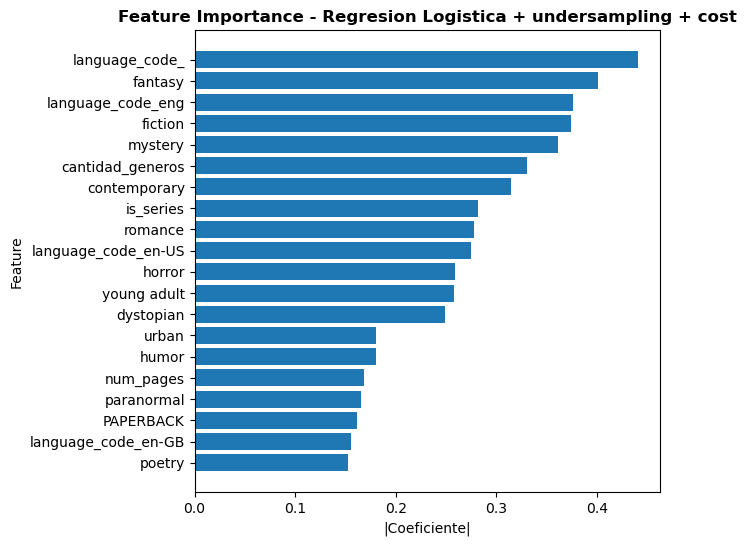

In [51]:
coeficientes_regresion_log_undersampling = pd.DataFrame({"feature": features, "coef": rebalanceo_3.coef_[0]})
coeficientes_regresion_log_undersampling["abs_coef"] = np.abs(coeficientes_regresion_log_undersampling["coef"])
coeficientes_regresion_log_undersampling = coeficientes_regresion_log_undersampling.sort_values("abs_coef", ascending = False)
plot_feature_importance_regression(coeficientes_regresion_log_undersampling, "Logistica + undersampling + cost")

In [54]:
print("Comparacion de tablas de metricas segun los diferentes rebalanceos")

print("\nModelo sin rebalanceo")
print(tabla_metricas_regresion_logistica_base)

print("\nModelo con rebalanceo predeterminado")
print(tabla_metricas_regresion_logistica_1)

print("\nModelo con rebalanceo con pesos definidos:")
print(tabla_metricas_regresion_logistica_2)

print("\nModelo con undersampling + cost")
print(tabla_metricas_regresion_logistica_3)

Comparacion de tablas de metricas segun los diferentes rebalanceos

Modelo sin rebalanceo
              Train  Validation
Accuracy   0.817427    0.814322
Precision  0.364093    0.427180
Recall     0.201451    0.201985
F1         0.182918    0.183565

Modelo con rebalanceo predeterminado
              Train  Validation
Accuracy   0.432199    0.429141
Precision  0.244453    0.243697
Recall     0.557401    0.547996
F1         0.207587    0.206194

Modelo con rebalanceo con pesos definidos:
              Train  Validation
Accuracy   0.791624    0.789114
Precision  0.283097    0.287245
Recall     0.252232    0.252603
F1         0.248450    0.249033

Modelo con undersampling + cost
              Train  Validation
Accuracy   0.729901    0.725521
Precision  0.271378    0.269997
Recall     0.280184    0.279348
F1         0.275165    0.273983


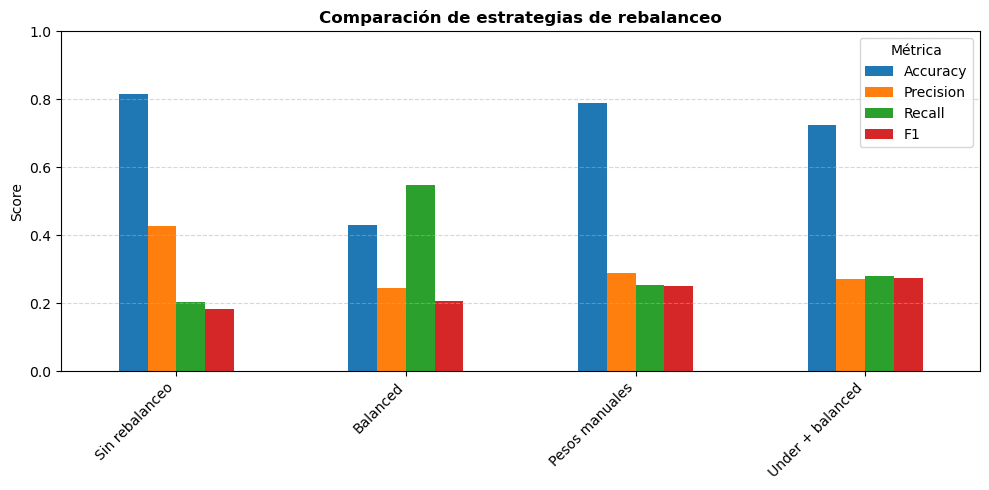

In [53]:
metricas = {"Sin rebalanceo": metricas_val_base, "Balanced": metricas_val_balanced, "Pesos manuales": metricas_val_manual, "Under + balanced": metricas_val_undersampling}
plot_comparacion_metricas(metricas, "Comparación de estrategias de rebalanceo")

A partir de estos resultados, podemos decir que: 

* Modelo sin rebalanceo --> posee el comportamiento esperado para clases desbalanceadas: accuracy muy alto, precision baja, y recall y F1-Score bajisimos. De seguro esta prediciendo la clase mayoritaria la mayoria de las veces.

* Modelo con rebalanceo predeterminado --> hace lo contrario al modelo sin rebalanceo: el recall sube mucho, pero el accuracy cae notoriamente. Esto se debe a que el modelo esta tratando de recuperar las clases minoritarias.

* Modelo con rebalanceo con pesos definidos --> tiene un buen accuracy y, respecto al baseline, el recall y F1-Socre suben mucho. En cuanto a metricas, este en un modelo mucho mas equilibrado, en comapracion a los 2 anteriores.

* Modelo con undersampling + cost --> tiene el mejor F1-Score y, por lo tanto, el mejor equilibrio entre precision y recall. Ademas, sus metricas de train y val son muy parecidas, indicando que el modelo generaliza muy bien (no muestra comportamiento de overfitting).

Ahora, si bien el modelo con rebalanceo predertimando fue el unico capaz de generar predicciones para todas las clases (segun su matriz de confusion), este modelo presenta valores muy bajos para accuracy y F1-Score. Esto signfica que el modelo sufrio un trade-off entre tratar de aumentar las predicciones a clases minoritarias, por un aumento en false positives. 

En cambio, el modelo de undersamplig + cost, obtuvo el mayor F1-Score, aun cuando las clases minoritarias continuaron sin ser correctamente identificadas. 

Por lo tanto, para esta primera fase, para el problema de clasificacion, nos quedamos con el modelo de undersampling + cost.